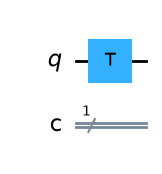

Statevector after T gate:
Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
Theta (θ) = 0.000 rad
Phi (φ) = 0.000 rad


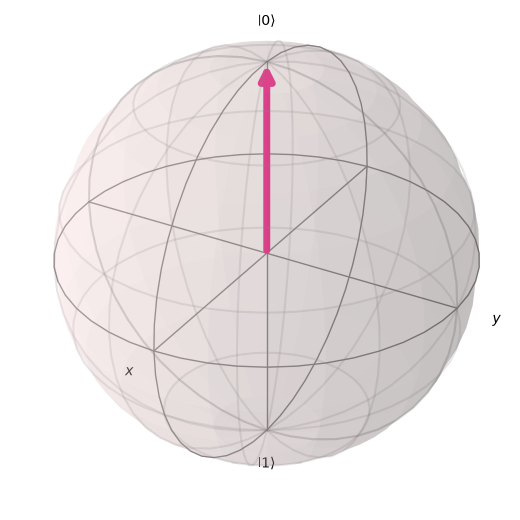

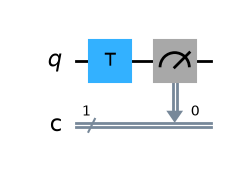

Measurement Results: {'0': 1024}


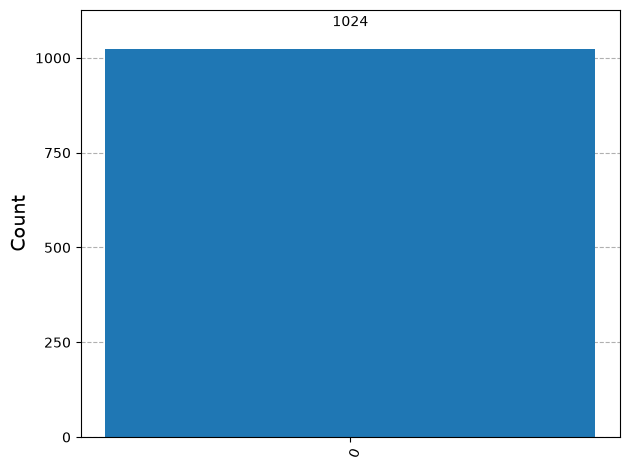


FINAL INTERPRETATION:
T gate adds a π/4 phase to |1>. |0> remains unchanged.
For superposition states (like |+>), vector rotates around Z-axis by φ = π/4.


In [1]:
# ============================================================
# T Gate Demonstration in Qiskit
# ============================================================

%matplotlib inline
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_vector
from matplotlib import pyplot as plt

# STEP 1: Create 1-qubit circuit
qc = QuantumCircuit(1,1)

# STEP 2: Apply T gate

qc.t(0)
qc.draw('mpl')
plt.show()

# STEP 3: Statevector
state = Statevector.from_instruction(qc)
print("Statevector after T gate:")
print(state)

# STEP 4: Compute θ and φ for Bloch sphere
a, b = state.data
theta = 2 * np.arccos(np.abs(a))
phi = np.angle(b) - np.angle(a)

print(f"Theta (θ) = {theta:.3f} rad")
print(f"Phi (φ) = {phi:.3f} rad")

# Bloch vector
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)
plot_bloch_vector([x, y, z])
plt.show()

# STEP 5: Measurement
qc.measure(0,0)
qc.draw('mpl')
plt.show()

# STEP 6: Simulation
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()
print("Measurement Results:", counts)
plot_histogram(counts)
plt.show()

print("\nFINAL INTERPRETATION:")
print("T gate adds a π/4 phase to |1>. |0> remains unchanged.")
print("For superposition states (like |+>), vector rotates around Z-axis by φ = π/4.")